<a href="https://www.kaggle.com/code/lalit7881/hospital-management-eda-94?scriptVersionId=362336027" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/deeplumiere/hospital-management-data/clinical_details.csv
/kaggle/input/datasets/deeplumiere/hospital-management-data/hospital_billing.csv
/kaggle/input/datasets/deeplumiere/hospital-management-data/hospital_management_system.xlsx
/kaggle/input/datasets/deeplumiere/hospital-management-data/patients.csv
/kaggle/input/datasets/deeplumiere/hospital-management-data/pharmacy_prescriptions.csv
/kaggle/input/datasets/deeplumiere/hospital-management-data/visits_encounters.csv


In [2]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
plt.switch_backend('Agg')
%matplotlib inline
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_curve, auc, accuracy_score
from sklearn.inspection import permutation_importance
from pathlib import Path
sns.set(style='whitegrid')

## Loading dataset

In [3]:
DATA_ROOTS = [
    Path('/kaggle/input'),
    Path('/kaggle/input'),
    Path('/kaggle/input/datasets'),
]

def resolve_data_file(file_name=None, suffixes=None):
    """
    Resolves file path from predefined roots.
    """
    suffixes = tuple(suffixes or [])
    for root in DATA_ROOTS:
        if not root.exists():
            continue
        matches = [p for p in root.rglob('*') if p.is_file()]
        if file_name:
            exact = [p for p in matches if p.name == file_name]
            if exact:
                return exact[0]
        if suffixes:
            typed = [p for p in matches if p.suffix.lower() in suffixes]
            if typed:
                return typed[0]
    raise FileNotFoundError(f'Could not resolve data file: {file_name or suffixes}')

In [4]:
visits_file = resolve_data_file(file_name='visits_encounters.csv', suffixes=['.csv'])
df_visits = pd.read_csv(visits_file, encoding='ascii')

In [5]:
print('visits_encounters data loaded successfully.')

visits_encounters data loaded successfully.


In [6]:
print('Dataframe shape:', df_visits.shape)
print('Columns:', df_visits.columns.tolist())

Dataframe shape: (13214, 18)
Columns: ['encounter_id', 'patient_id', 'encounter_type', 'admission_datetime', 'discharge_datetime', 'length_of_stay_days', 'admission_urgency', 'department', 'attending_physician_id', 'icu_admitted', 'icu_days', 'discharge_disposition', 'news2_acuity_score', 'revisit_count', 'previous_encounter_id', 'days_since_last_discharge', 'readmission_30d', 'in_hospital_mortality']


In [7]:
df_visits.head()

,encounter_id,patient_id,encounter_type,admission_datetime,discharge_datetime,length_of_stay_days,admission_urgency,department,attending_physician_id,icu_admitted,icu_days,discharge_disposition,news2_acuity_score,revisit_count,previous_encounter_id,days_since_last_discharge,readmission_30d,in_hospital_mortality
0,ENC-100001,PAT-10001,Emergency,2023-03-30 00:00:00,2023-04-03 07:12:00,4.30,Emergency,General Medicine,DOC-106,0,0.0,Skilled Nursing Facility,1,1,NaN,NaN,0,0
1,ENC-100002,PAT-10001,Outpatient,2023-04-06 12:00:00,2023-04-06 16:19:12,0.18,Elective,General Medicine,DOC-151,0,0.0,Home,2,2,ENC-100001,3.2,0,0
2,ENC-100003,PAT-10001,Outpatient,2023-04-18 04:19:12,2023-04-18 13:55:12,0.40,Elective,Cardiology,DOC-111,0,0.0,Home,9,3,ENC-100002,11.5,1,0
3,ENC-100004,PAT-10002,Emergency,2023-03-28 00:00:00,2023-04-07 19:12:00,10.80,Emergency,Cardiology,DOC-115,0,0.0,Home,7,1,NaN,NaN,1,0
4,ENC-100005,PAT-10002,Inpatient,2023-04-09 12:00:00,2023-04-12 16:48:00,3.20,Urgent,General Medicine,DOC-134,0,0.0,Home,0,2,ENC-100004,1.7,1,0


In [8]:
df_visits.tail()

,encounter_id,patient_id,encounter_type,admission_datetime,discharge_datetime,length_of_stay_days,admission_urgency,department,attending_physician_id,icu_admitted,icu_days,discharge_disposition,news2_acuity_score,revisit_count,previous_encounter_id,days_since_last_discharge,readmission_30d,in_hospital_mortality
13209,ENC-113210,PAT-14998,Inpatient,2023-07-15 18:43:12,2023-07-22 09:07:12,6.60,Emergency,Cardiology,NaN,0,0.0,Skilled Nursing Facility,5,2,ENC-113209,137.5,1,0
13210,ENC-113211,PAT-14998,Emergency,2023-08-07 23:31:12,2023-08-14 23:31:12,7.00,Emergency,Cardiology,DOC-104,0,0.0,Home,8,3,ENC-113210,16.6,1,0
13211,ENC-113212,PAT-14999,Outpatient,2023-04-04 00:00:00,2023-04-04 05:45:36,0.24,Urgent,General Medicine,DOC-119,0,0.0,Home,5,1,NaN,NaN,1,0
13212,ENC-113213,PAT-15000,Outpatient,2023-01-02 00:00:00,2023-01-02 09:50:24,0.41,Urgent,Cardiology,DOC-101,0,0.0,Home,4,1,NaN,NaN,0,0
13213,ENC-113214,PAT-15000,Inpatient,2023-05-16 02:38:24,2023-05-20 21:50:24,4.80,Emergency,General Surgery,DOC-150,0,0.0,Home,3,2,ENC-113213,133.7,0,0


In [9]:
df_visits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13214 entries, 0 to 13213
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   encounter_id               13214 non-null  object 
 1   patient_id                 13214 non-null  object 
 2   encounter_type             13214 non-null  object 
 3   admission_datetime         13214 non-null  object 
 4   discharge_datetime         13214 non-null  object 
 5   length_of_stay_days        13214 non-null  float64
 6   admission_urgency          13214 non-null  object 
 7   department                 13214 non-null  object 
 8   attending_physician_id     12475 non-null  object 
 9   icu_admitted               13214 non-null  int64  
 10  icu_days                   13214 non-null  float64
 11  discharge_disposition      12509 non-null  object 
 12  news2_acuity_score         13214 non-null  int64  
 13  revisit_count              13214 non-null  int

In [10]:
df_visits.describe()

,length_of_stay_days,icu_admitted,icu_days,news2_acuity_score,revisit_count,days_since_last_discharge,readmission_30d,in_hospital_mortality
count,13214.000000,13214.000000,13214.000000,13214.000000,13214.000000,8214.000000,13214.000000,13214.000000
mean,5.758047,0.040714,0.209664,5.504011,2.275087,106.582189,0.330256,0.100954
std,7.055869,0.197635,1.223506,3.889191,1.367611,103.507973,0.470323,0.301279
min,0.150000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,0.330000,0.000000,0.000000,2.000000,1.000000,10.300000,0.000000,0.000000
50%,3.600000,0.000000,0.000000,5.000000,2.000000,70.350000,0.000000,0.000000
75%,8.500000,0.000000,0.000000,8.000000,3.000000,196.800000,1.000000,0.000000
max,34.000000,1.000000,14.000000,18.000000,6.000000,320.000000,1.000000,1.000000


In [11]:
df_visits.isnull().sum()

encounter_id                    0
patient_id                      0
encounter_type                  0
admission_datetime              0
discharge_datetime              0
length_of_stay_days             0
admission_urgency               0
department                      0
attending_physician_id        739
icu_admitted                    0
icu_days                        0
discharge_disposition         705
news2_acuity_score              0
revisit_count                   0
previous_encounter_id        5000
days_since_last_discharge    5000
readmission_30d                 0
in_hospital_mortality           0
dtype: int64

In [12]:
df_visits.duplicated().sum()

np.int64(0)

In [13]:
df_visits.dtypes

encounter_id                  object
patient_id                    object
encounter_type                object
admission_datetime            object
discharge_datetime            object
length_of_stay_days          float64
admission_urgency             object
department                    object
attending_physician_id        object
icu_admitted                   int64
icu_days                     float64
discharge_disposition         object
news2_acuity_score             int64
revisit_count                  int64
previous_encounter_id         object
days_since_last_discharge    float64
readmission_30d                int64
in_hospital_mortality          int64
dtype: object

In [14]:
df_visits.shape

(13214, 18)

In [15]:
df_visits.columns

Index(['encounter_id', 'patient_id', 'encounter_type', 'admission_datetime',
       'discharge_datetime', 'length_of_stay_days', 'admission_urgency',
       'department', 'attending_physician_id', 'icu_admitted', 'icu_days',
       'discharge_disposition', 'news2_acuity_score', 'revisit_count',
       'previous_encounter_id', 'days_since_last_discharge', 'readmission_30d',
       'in_hospital_mortality'],
      dtype='object')

In [16]:
df_visits.nunique()

encounter_id                 13214
patient_id                    5000
encounter_type                   3
admission_datetime            7161
discharge_datetime            9867
length_of_stay_days            381
admission_urgency                3
department                       8
attending_physician_id          60
icu_admitted                     2
icu_days                       121
discharge_disposition            6
news2_acuity_score              19
revisit_count                    6
previous_encounter_id         8214
days_since_last_discharge     2635
readmission_30d                  2
in_hospital_mortality            2
dtype: int64


## Feature engineering

HOSPITAL VISITS DATASET OVERVIEW

Dataset Shape: (13214, 18)

Column Names:
 ['encounter_id', 'patient_id', 'encounter_type', 'admission_datetime', 'discharge_datetime', 'length_of_stay_days', 'admission_urgency', 'department', 'attending_physician_id', 'icu_admitted', 'icu_days', 'discharge_disposition', 'news2_acuity_score', 'revisit_count', 'previous_encounter_id', 'days_since_last_discharge', 'readmission_30d', 'in_hospital_mortality']

First 5 Rows:


,encounter_id,patient_id,encounter_type,admission_datetime,discharge_datetime,length_of_stay_days,admission_urgency,department,attending_physician_id,icu_admitted,icu_days,discharge_disposition,news2_acuity_score,revisit_count,previous_encounter_id,days_since_last_discharge,readmission_30d,in_hospital_mortality
0,ENC-100001,PAT-10001,Emergency,2023-03-30 00:00:00,2023-04-03 07:12:00,4.30,Emergency,General Medicine,DOC-106,0,0.0,Skilled Nursing Facility,1,1,NaN,NaN,0,0
1,ENC-100002,PAT-10001,Outpatient,2023-04-06 12:00:00,2023-04-06 16:19:12,0.18,Elective,General Medicine,DOC-151,0,0.0,Home,2,2,ENC-100001,3.2,0,0
2,ENC-100003,PAT-10001,Outpatient,2023-04-18 04:19:12,2023-04-18 13:55:12,0.40,Elective,Cardiology,DOC-111,0,0.0,Home,9,3,ENC-100002,11.5,1,0
3,ENC-100004,PAT-10002,Emergency,2023-03-28 00:00:00,2023-04-07 19:12:00,10.80,Emergency,Cardiology,DOC-115,0,0.0,Home,7,1,NaN,NaN,1,0
4,ENC-100005,PAT-10002,Inpatient,2023-04-09 12:00:00,2023-04-12 16:48:00,3.20,Urgent,General Medicine,DOC-134,0,0.0,Home,0,2,ENC-100004,1.7,1,0



Data Types:
encounter_id                  object
patient_id                    object
encounter_type                object
admission_datetime            object
discharge_datetime            object
length_of_stay_days          float64
admission_urgency             object
department                    object
attending_physician_id        object
icu_admitted                   int64
icu_days                     float64
discharge_disposition         object
news2_acuity_score             int64
revisit_count                  int64
previous_encounter_id         object
days_since_last_discharge    float64
readmission_30d                int64
in_hospital_mortality          int64
dtype: object

Missing Values:
encounter_id                    0
patient_id                      0
encounter_type                  0
admission_datetime              0
discharge_datetime              0
length_of_stay_days             0
admission_urgency               0
department                      0
attending_physicia

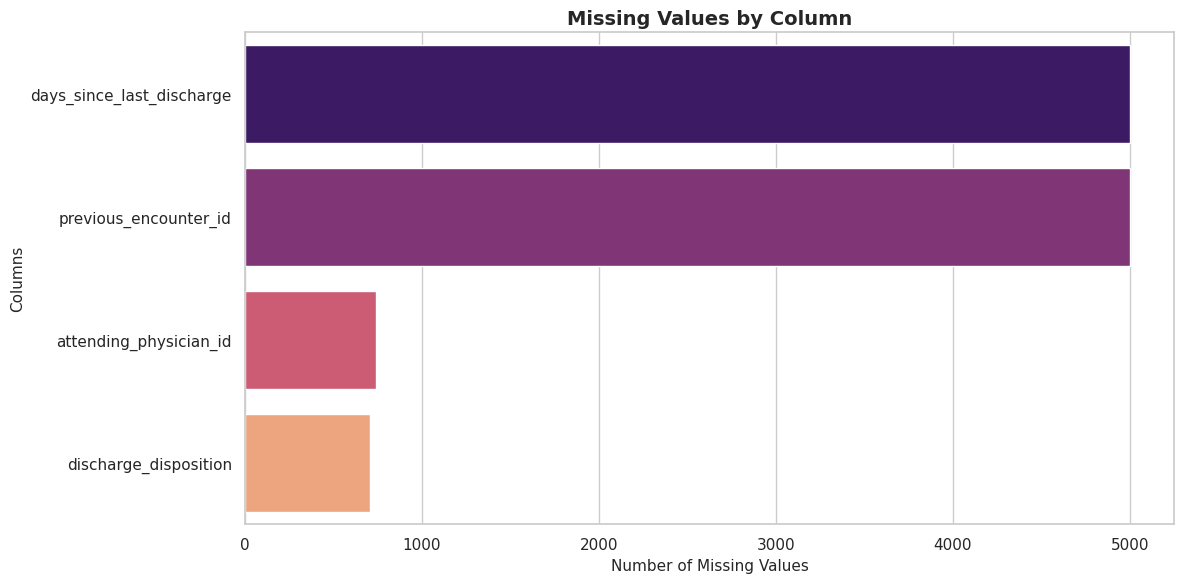

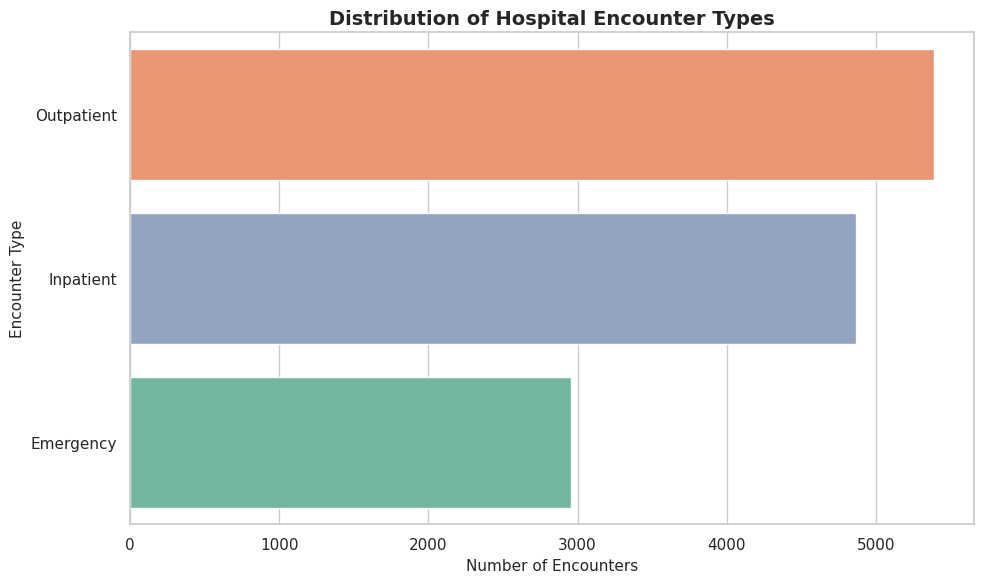

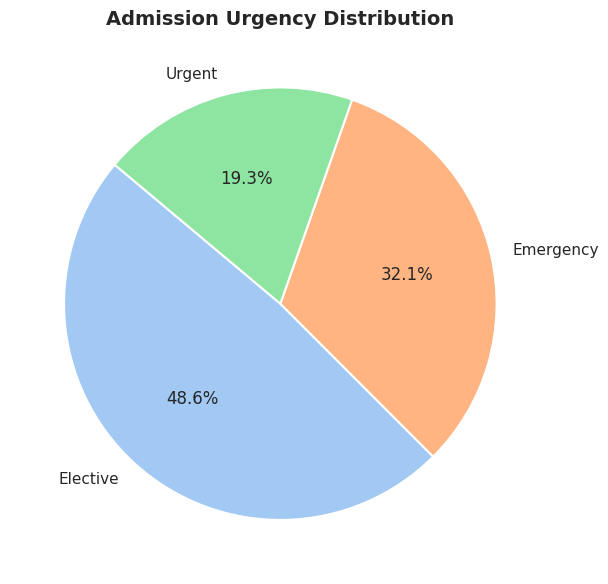

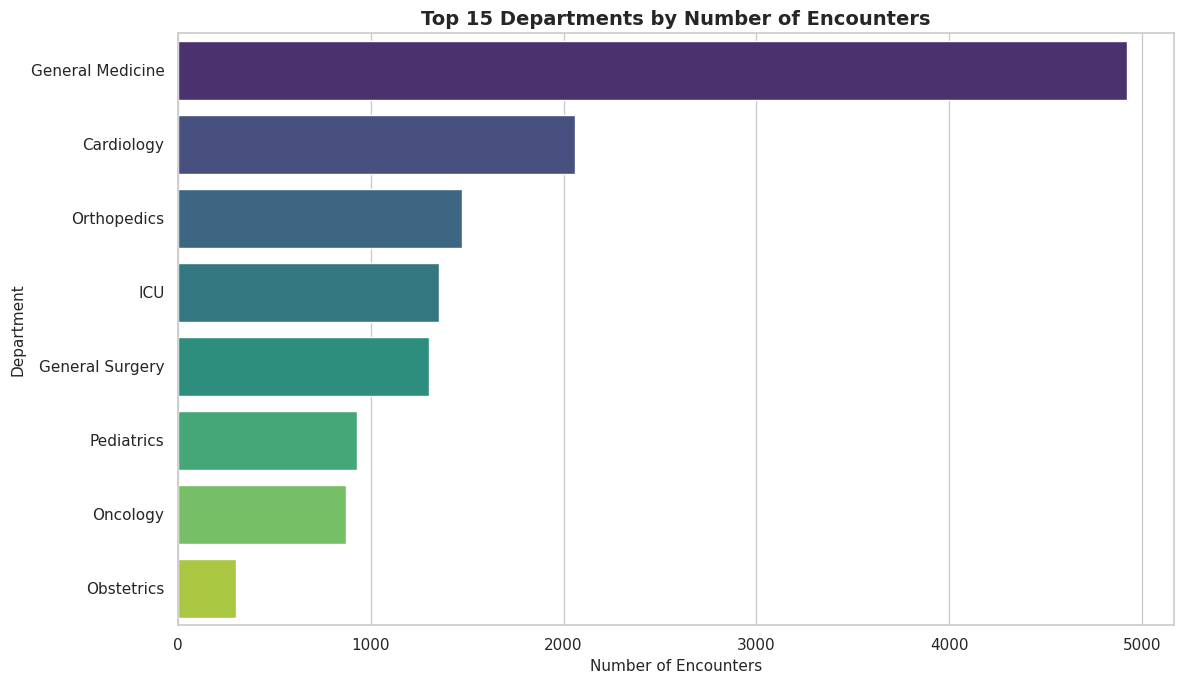

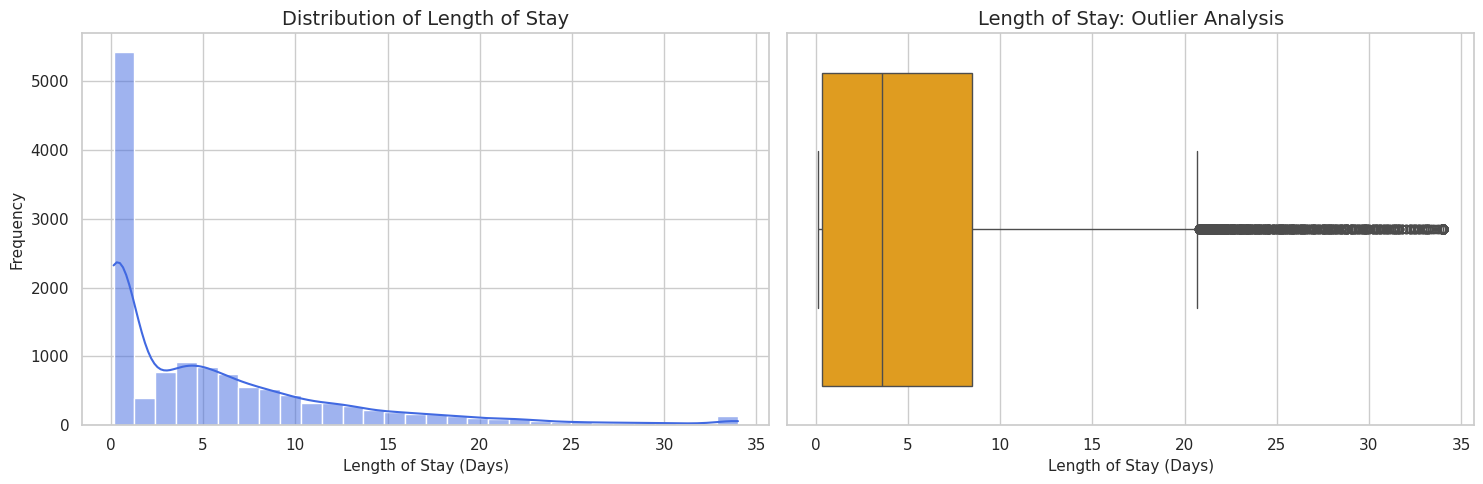

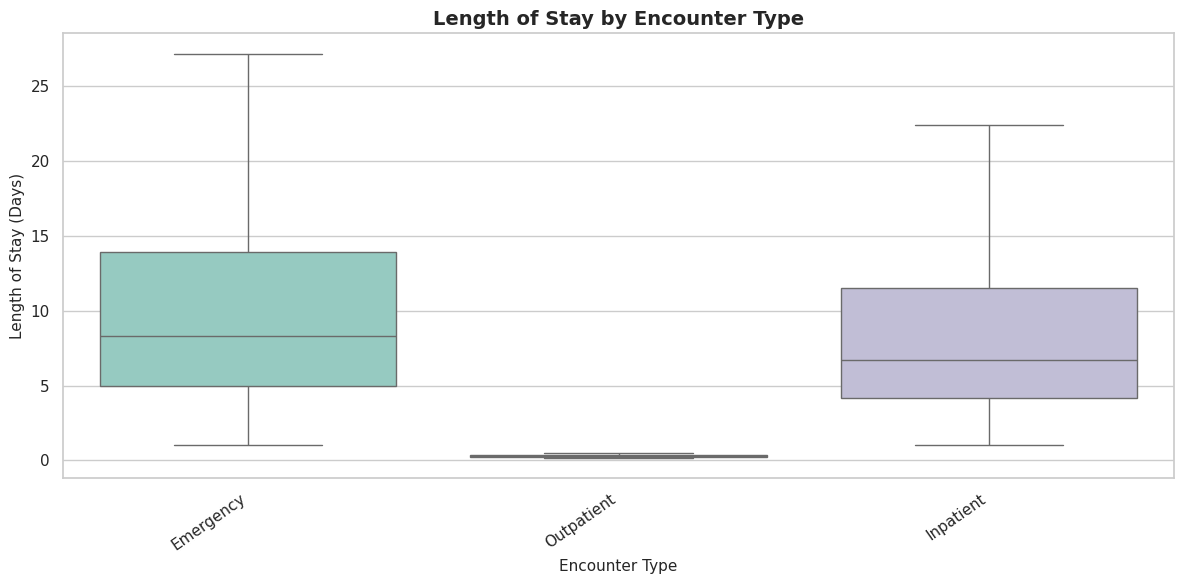

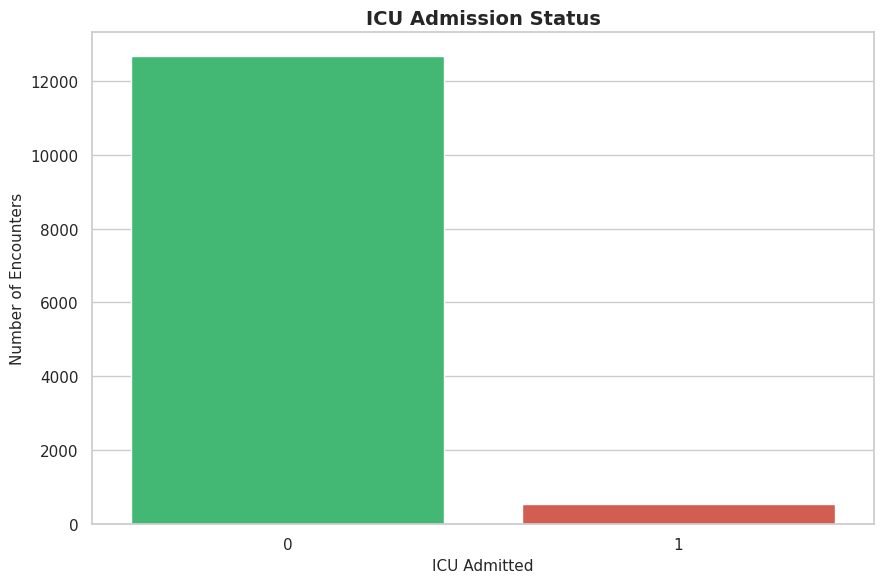

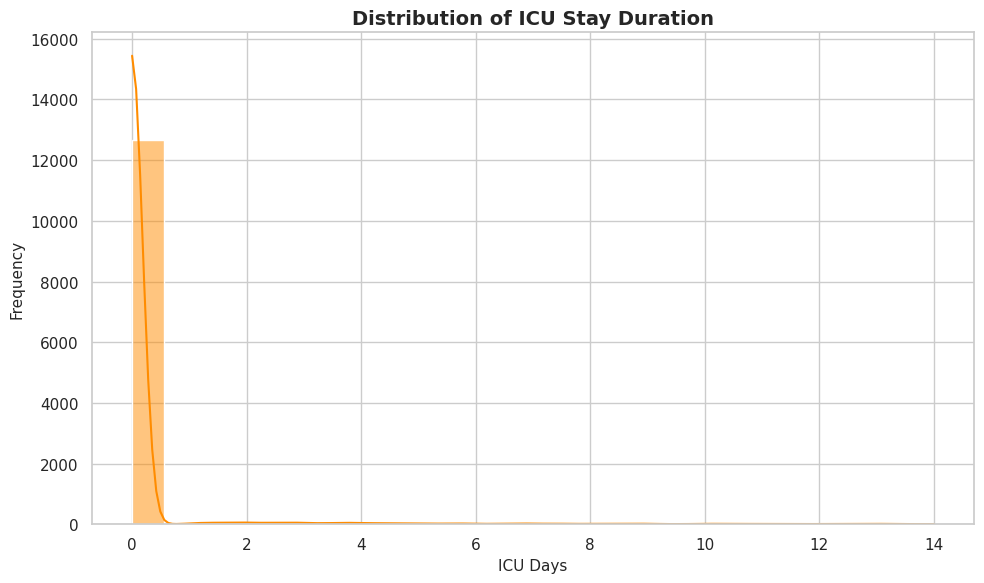

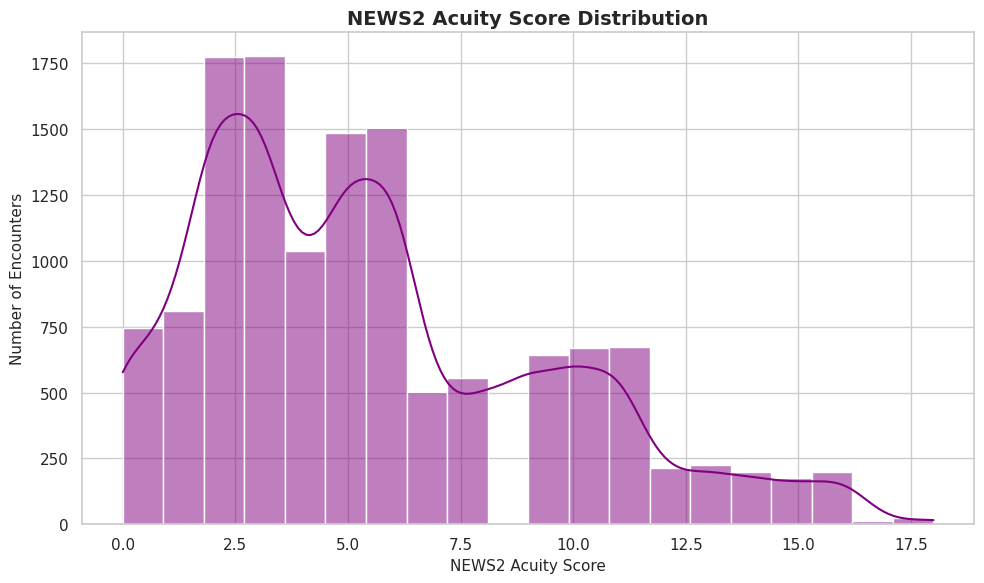

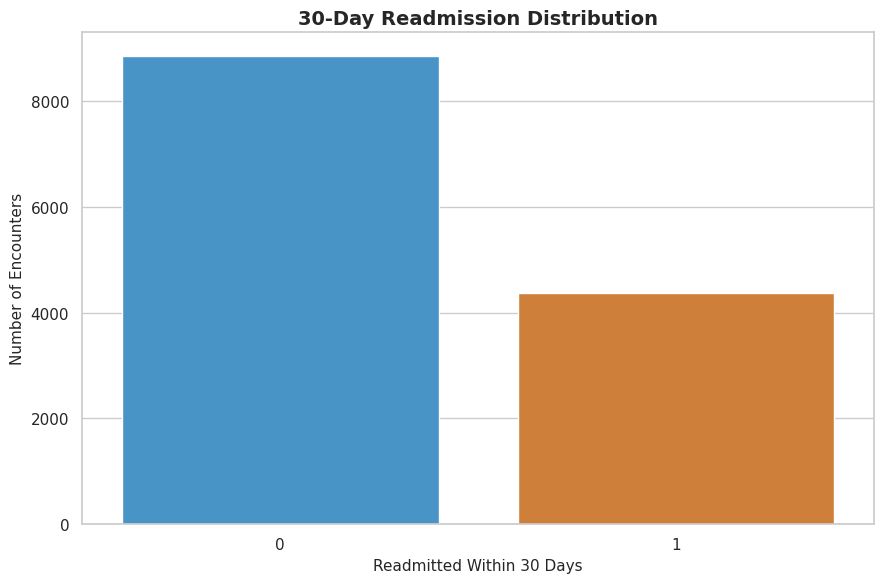

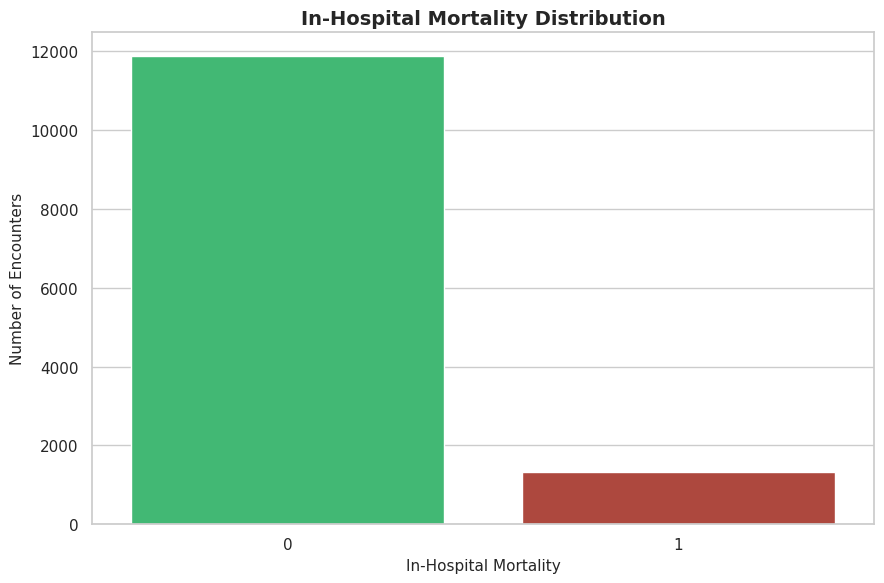

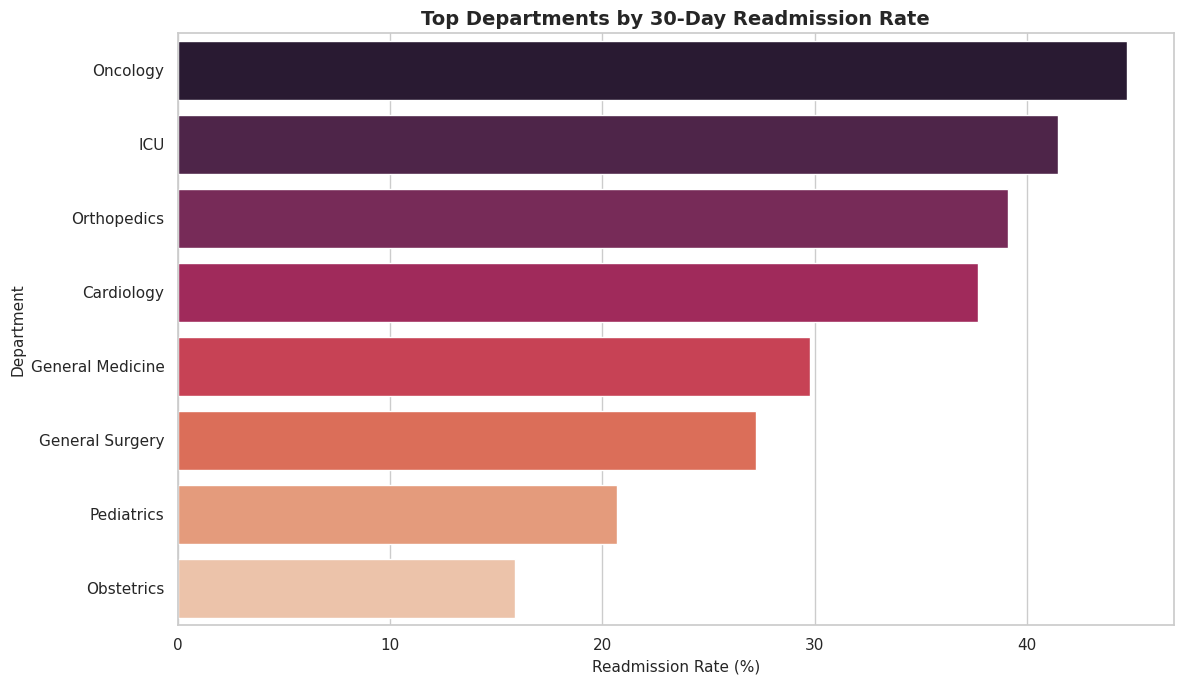

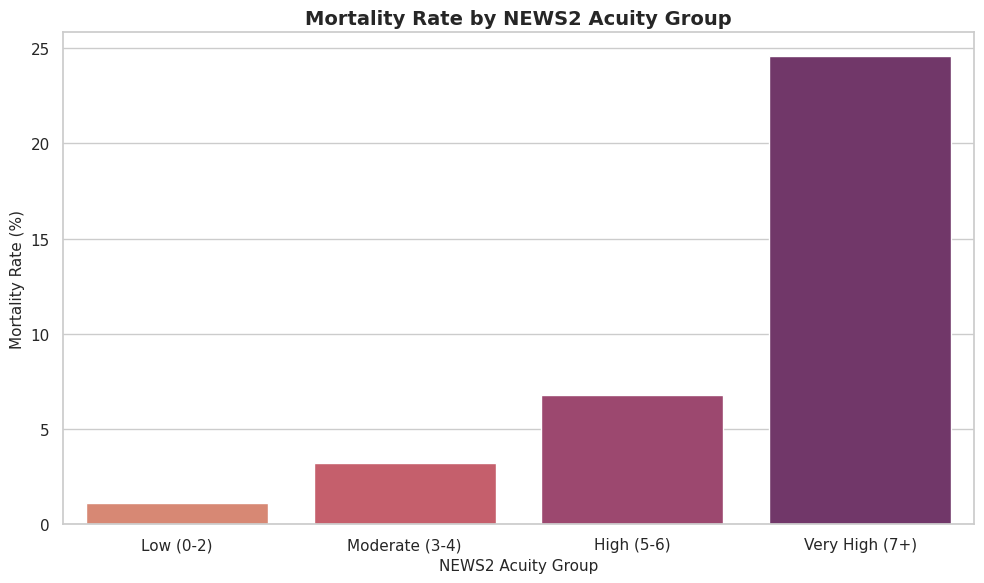

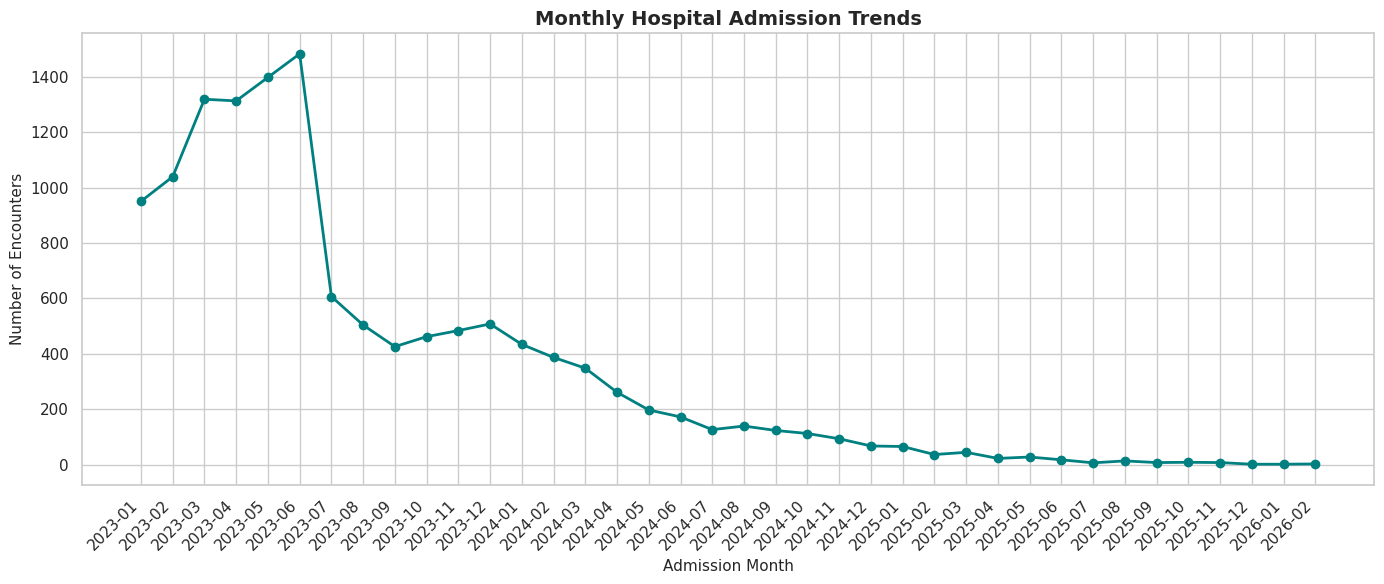

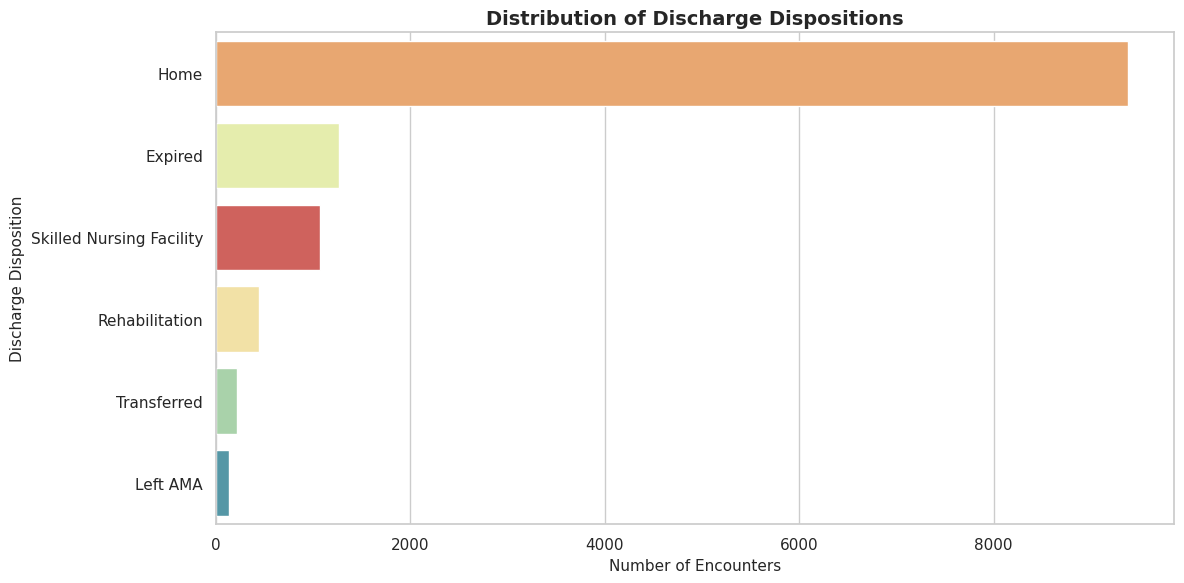

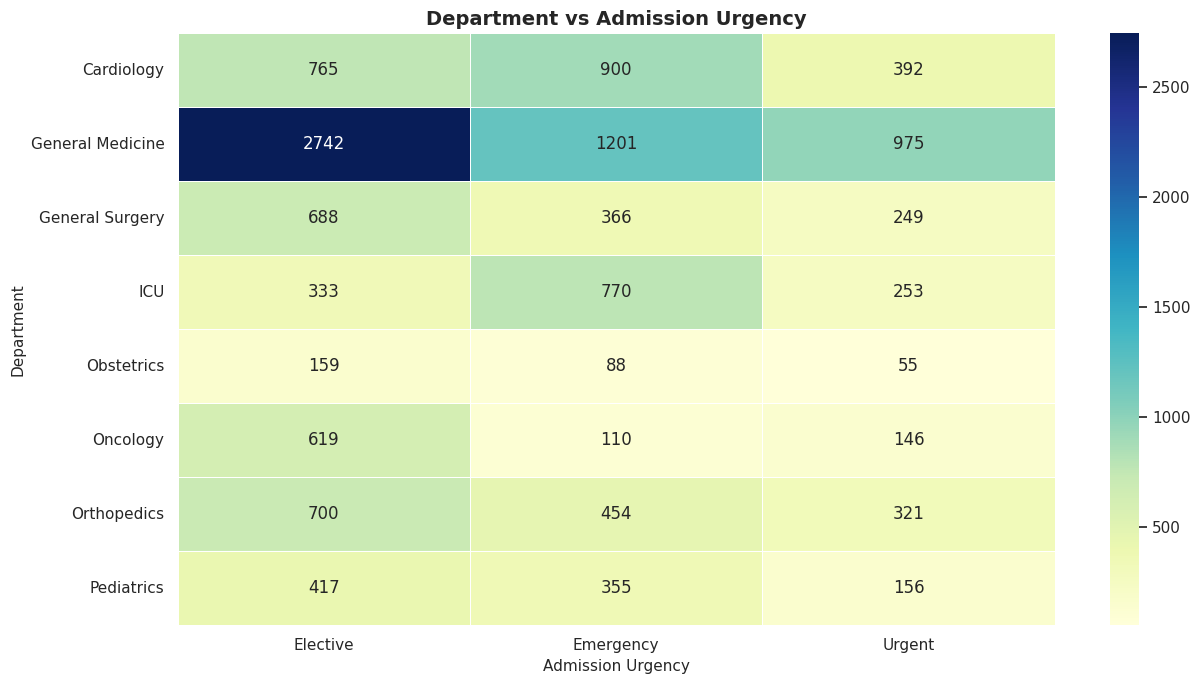

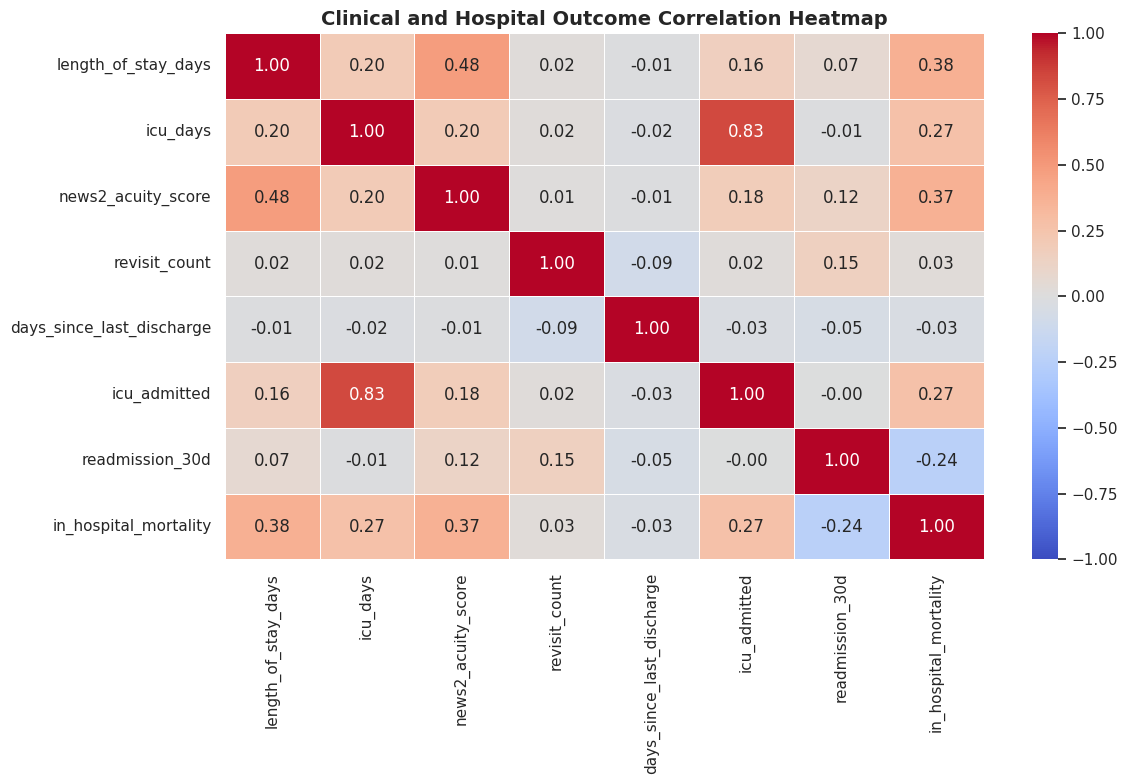

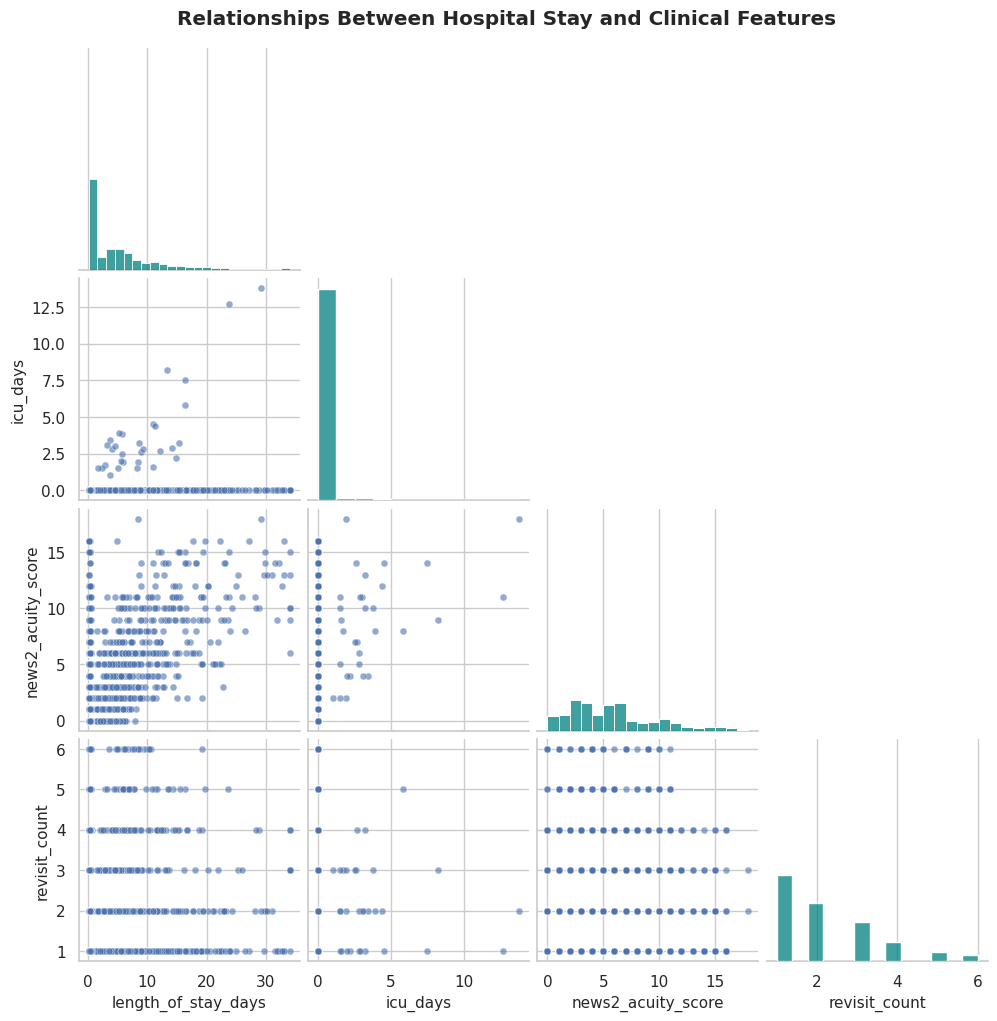


HOSPITAL ENCOUNTER SUMMARY

Total Encounters: 13214
Unique Patients: 5000
Unique Departments: 8

Numerical Summary:


,length_of_stay_days,icu_days,news2_acuity_score,revisit_count,days_since_last_discharge
count,13214.00,13214.00,13214.00,13214.00,8214.00
mean,5.76,0.21,5.50,2.28,106.58
std,7.06,1.22,3.89,1.37,103.51
min,0.15,0.00,0.00,1.00,1.00
25%,0.33,0.00,2.00,1.00,10.30
50%,3.60,0.00,5.00,2.00,70.35
75%,8.50,0.00,8.00,3.00,196.80
max,34.00,14.00,18.00,6.00,320.00



Encounter Types:


,Count
encounter_type,
Outpatient,5389
Inpatient,4867
Emergency,2958



Department Counts:


,Count
department,
General Medicine,4918
Cardiology,2057
Orthopedics,1475
ICU,1356
General Surgery,1303
Pediatrics,928
Oncology,875
Obstetrics,302



Visualization completed successfully!


In [17]:
# ============================================================
# HOSPITAL VISITS & PATIENT OUTCOMES - DATA VISUALIZATION
# Dataset: df_visits
# ============================================================

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Set visualization style
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

# Check dataset
print("=" * 70)
print("HOSPITAL VISITS DATASET OVERVIEW")
print("=" * 70)

print("\nDataset Shape:", df_visits.shape)
print("\nColumn Names:\n", df_visits.columns.tolist())
print("\nFirst 5 Rows:")
display(df_visits.head())

print("\nData Types:")
print(df_visits.dtypes)

print("\nMissing Values:")
print(df_visits.isnull().sum())

# Work on a copy
df_visits = df_visits.copy()

# Convert date columns
date_cols = ["admission_datetime", "discharge_datetime"]

for col in date_cols:
    df_visits[col] = pd.to_datetime(df_visits[col], errors="coerce")

# Convert numeric columns safely
numeric_cols = [
    "length_of_stay_days",
    "icu_days",
    "news2_acuity_score",
    "revisit_count",
    "days_since_last_discharge"
]

for col in numeric_cols:
    df_visits[col] = pd.to_numeric(df_visits[col], errors="coerce")

# Standardize common binary fields for plotting
binary_cols = [
    "icu_admitted",
    "readmission_30d",
    "in_hospital_mortality"
]

for col in binary_cols:
    if col in df_visits.columns:
        df_visits[col] = df_visits[col].replace({
            "Yes": 1, "No": 0,
            "yes": 1, "no": 0,
            "True": 1, "False": 0,
            True: 1, False: 0
        })

# Different colors for different charts
palette1 = "viridis"
palette2 = "Set2"
palette3 = "Set3"
palette4 = "coolwarm"
palette5 = "magma"
palette6 = "husl"


# ============================================================
# 2. MISSING VALUES VISUALIZATION
# ============================================================

missing = df_visits.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) > 0:
    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=missing.values,
        y=missing.index,
        hue=missing.index,
        palette=palette5,
        legend=False
    )
    plt.title("Missing Values by Column", fontweight="bold")
    plt.xlabel("Number of Missing Values")
    plt.ylabel("Columns")
    plt.tight_layout()
    plt.show()
else:
    print("\nNo missing values found.")


# ============================================================
# 3. ENCOUNTER TYPE DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))
order = df_visits["encounter_type"].value_counts().index

sns.countplot(
    data=df_visits,
    y="encounter_type",
    hue="encounter_type",
    order=order,
    palette=palette2,
    legend=False
)

plt.title("Distribution of Hospital Encounter Types", fontweight="bold")
plt.xlabel("Number of Encounters")
plt.ylabel("Encounter Type")
plt.tight_layout()
plt.show()


# ============================================================
# 4. ADMISSION URGENCY DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))
urgency_counts = df_visits["admission_urgency"].value_counts()

plt.pie(
    urgency_counts.values,
    labels=urgency_counts.index.astype(str),
    autopct="%1.1f%%",
    startangle=140,
    colors=sns.color_palette("pastel", len(urgency_counts)),
    wedgeprops={"edgecolor": "white", "linewidth": 1.5}
)

plt.title("Admission Urgency Distribution", fontweight="bold")
plt.tight_layout()
plt.show()


# ============================================================
# 5. DEPARTMENT-WISE ENCOUNTERS
# ============================================================

department_counts = df_visits["department"].value_counts().head(15)

plt.figure(figsize=(12, 7))
sns.barplot(
    x=department_counts.values,
    y=department_counts.index,
    hue=department_counts.index,
    palette=palette1,
    legend=False
)

plt.title("Top 15 Departments by Number of Encounters",
          fontweight="bold")
plt.xlabel("Number of Encounters")
plt.ylabel("Department")
plt.tight_layout()
plt.show()


# ============================================================
# 6. LENGTH OF STAY DISTRIBUTION
# ============================================================

los = df_visits["length_of_stay_days"].dropna()
los = los[los >= 0]

if not los.empty:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    sns.histplot(
        los,
        bins=30,
        kde=True,
        color="royalblue",
        ax=axes[0]
    )
    axes[0].set_title("Distribution of Length of Stay")
    axes[0].set_xlabel("Length of Stay (Days)")
    axes[0].set_ylabel("Frequency")

    sns.boxplot(
        x=los,
        color="orange",
        ax=axes[1]
    )
    axes[1].set_title("Length of Stay: Outlier Analysis")
    axes[1].set_xlabel("Length of Stay (Days)")

    plt.tight_layout()
    plt.show()


# ============================================================
# 7. LENGTH OF STAY BY ENCOUNTER TYPE
# ============================================================

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_visits,
    x="encounter_type",
    y="length_of_stay_days",
    hue="encounter_type",
    palette=palette3,
    showfliers=False,
    legend=False
)

plt.title("Length of Stay by Encounter Type", fontweight="bold")
plt.xlabel("Encounter Type")
plt.ylabel("Length of Stay (Days)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


# ============================================================
# 8. ICU ADMISSION DISTRIBUTION
# ============================================================

icu_counts = df_visits["icu_admitted"].value_counts(dropna=False)

plt.figure(figsize=(9, 6))
sns.barplot(
    x=icu_counts.index.astype(str),
    y=icu_counts.values,
    hue=icu_counts.index.astype(str),
    palette=["#2ecc71", "#e74c3c", "#95a5a6"][:len(icu_counts)],
    legend=False
)

plt.title("ICU Admission Status", fontweight="bold")
plt.xlabel("ICU Admitted")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()


# ============================================================
# 9. ICU DAYS DISTRIBUTION
# ============================================================

icu_days = df_visits["icu_days"].dropna()
icu_days = icu_days[icu_days >= 0]

if not icu_days.empty:
    plt.figure(figsize=(10, 6))
    sns.histplot(
        icu_days,
        bins=25,
        kde=True,
        color="darkorange"
    )
    plt.title("Distribution of ICU Stay Duration", fontweight="bold")
    plt.xlabel("ICU Days")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


# ============================================================
# 10. NEWS2 ACUITY SCORE DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_visits,
    x="news2_acuity_score",
    bins=20,
    kde=True,
    color="purple"
)

plt.title("NEWS2 Acuity Score Distribution", fontweight="bold")
plt.xlabel("NEWS2 Acuity Score")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()


# ============================================================
# 11. READMISSION WITHIN 30 DAYS
# ============================================================

readmission_counts = df_visits["readmission_30d"].value_counts(
    dropna=False
)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=readmission_counts.index.astype(str),
    y=readmission_counts.values,
    hue=readmission_counts.index.astype(str),
    palette=["#3498db", "#e67e22", "#95a5a6"][:len(readmission_counts)],
    legend=False
)

plt.title("30-Day Readmission Distribution", fontweight="bold")
plt.xlabel("Readmitted Within 30 Days")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()


# ============================================================
# 12. IN-HOSPITAL MORTALITY DISTRIBUTION
# ============================================================

mortality_counts = df_visits["in_hospital_mortality"].value_counts(
    dropna=False
)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=mortality_counts.index.astype(str),
    y=mortality_counts.values,
    hue=mortality_counts.index.astype(str),
    palette=["#2ecc71", "#c0392b", "#95a5a6"][:len(mortality_counts)],
    legend=False
)

plt.title("In-Hospital Mortality Distribution", fontweight="bold")
plt.xlabel("In-Hospital Mortality")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()


# ============================================================
# 13. READMISSION RATE BY DEPARTMENT
# ============================================================

temp = df_visits.copy()
temp["readmission_numeric"] = pd.to_numeric(
    temp["readmission_30d"], errors="coerce"
)

# Only calculate a rate when the field is binary
valid_readmission = temp["readmission_numeric"].dropna().isin([0, 1]).all()

if valid_readmission:
    dept_readmission = (
        temp.groupby("department", observed=True)["readmission_numeric"]
        .mean()
        .dropna()
        .sort_values(ascending=False)
        .head(15) * 100
    )

    plt.figure(figsize=(12, 7))
    sns.barplot(
        x=dept_readmission.values,
        y=dept_readmission.index,
        hue=dept_readmission.index,
        palette="rocket",
        legend=False
    )
    plt.title("Top Departments by 30-Day Readmission Rate",
              fontweight="bold")
    plt.xlabel("Readmission Rate (%)")
    plt.ylabel("Department")
    plt.tight_layout()
    plt.show()
else:
    print("Readmission rate chart skipped: convert readmission_30d "
          "to a valid binary field (0/1) first.")


# ============================================================
# 14. MORTALITY BY NEWS2 ACUITY SCORE
# ============================================================

temp = df_visits.copy()
temp["mortality_numeric"] = pd.to_numeric(
    temp["in_hospital_mortality"], errors="coerce"
)

valid_mortality = (
    temp["mortality_numeric"].dropna().isin([0, 1]).all()
)

if valid_mortality:
    temp = temp.dropna(
        subset=["news2_acuity_score", "mortality_numeric"]
    )

    if not temp.empty:
        temp["acuity_group"] = pd.cut(
            temp["news2_acuity_score"],
            bins=[-np.inf, 2, 4, 6, np.inf],
            labels=["Low (0-2)", "Moderate (3-4)",
                    "High (5-6)", "Very High (7+)"]
        )

        mortality_by_acuity = (
            temp.groupby("acuity_group", observed=False)["mortality_numeric"]
            .mean()
            .dropna() * 100
        )

        plt.figure(figsize=(10, 6))
        sns.barplot(
            x=mortality_by_acuity.index,
            y=mortality_by_acuity.values,
            hue=mortality_by_acuity.index,
            palette="flare",
            legend=False
        )
        plt.title("Mortality Rate by NEWS2 Acuity Group",
                  fontweight="bold")
        plt.xlabel("NEWS2 Acuity Group")
        plt.ylabel("Mortality Rate (%)")
        plt.tight_layout()
        plt.show()
else:
    print("Mortality-by-acuity chart skipped: expected binary 0/1 values.")


# ============================================================
# 15. ADMISSIONS OVER TIME
# ============================================================

admissions = df_visits.dropna(subset=["admission_datetime"]).copy()

if not admissions.empty:
    admissions["admission_month"] = (
        admissions["admission_datetime"].dt.to_period("M").astype(str)
    )

    monthly_admissions = (
        admissions.groupby("admission_month")
        .size()
        .sort_index()
    )

    plt.figure(figsize=(14, 6))
    plt.plot(
        monthly_admissions.index,
        monthly_admissions.values,
        marker="o",
        linewidth=2,
        color="teal"
    )
    plt.title("Monthly Hospital Admission Trends", fontweight="bold")
    plt.xlabel("Admission Month")
    plt.ylabel("Number of Encounters")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


# ============================================================
# 16. DISCHARGE DISPOSITION
# ============================================================

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_visits,
    y="discharge_disposition",
    hue="discharge_disposition",
    order=df_visits["discharge_disposition"].value_counts().index,
    palette="Spectral",
    legend=False
)

plt.title("Distribution of Discharge Dispositions", fontweight="bold")
plt.xlabel("Number of Encounters")
plt.ylabel("Discharge Disposition")
plt.tight_layout()
plt.show()


# ============================================================
# 17. ENCOUNTERS BY DEPARTMENT AND URGENCY
# ============================================================

top_departments = df_visits["department"].value_counts().head(10).index

department_urgency = df_visits[
    df_visits["department"].isin(top_departments)
].pivot_table(
    index="department",
    columns="admission_urgency",
    values="encounter_id",
    aggfunc="count",
    fill_value=0,
    observed=False
)

plt.figure(figsize=(13, 7))
sns.heatmap(
    department_urgency,
    annot=True,
    fmt="g",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Department vs Admission Urgency", fontweight="bold")
plt.xlabel("Admission Urgency")
plt.ylabel("Department")
plt.tight_layout()
plt.show()


# ============================================================
# 18. CORRELATION HEATMAP
# ============================================================

corr_cols = [
    "length_of_stay_days",
    "icu_days",
    "news2_acuity_score",
    "revisit_count",
    "days_since_last_discharge"
]

# Include binary variables only if encoded as numeric
for col in binary_cols:
    if col in df_visits.columns:
        values = pd.to_numeric(df_visits[col], errors="coerce")
        if values.dropna().isin([0, 1]).all():
            df_visits[col] = values
            corr_cols.append(col)

corr_cols = [
    col for col in corr_cols
    if col in df_visits.columns
    and pd.api.types.is_numeric_dtype(df_visits[col])
]

corr_data = df_visits[corr_cols].replace([np.inf, -np.inf], np.nan)
corr_data = corr_data.dropna(axis=1, how="all")
correlation = corr_data.corr()

if correlation.shape[1] >= 2:
    plt.figure(figsize=(12, 8))
    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5,
        vmin=-1,
        vmax=1,
        center=0
    )
    plt.title("Clinical and Hospital Outcome Correlation Heatmap",
              fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for correlation heatmap.")


# ============================================================
# 19. NUMERIC FEATURE PAIR PLOT
# ============================================================

pair_cols = [
    "length_of_stay_days",
    "icu_days",
    "news2_acuity_score",
    "revisit_count"
]

pair_cols = [
    col for col in pair_cols
    if col in df_visits.columns
    and df_visits[col].notna().sum() > 1
    and df_visits[col].nunique() > 1
]

if len(pair_cols) >= 2:
    pair_data = df_visits[pair_cols].dropna()

    if len(pair_data) > 1:
        # Sample for faster rendering on large datasets
        if len(pair_data) > 1000:
            pair_data = pair_data.sample(1000, random_state=42)

        sns.pairplot(
            pair_data,
            diag_kind="hist",
            corner=True,
            plot_kws={"alpha": 0.6, "s": 25},
            diag_kws={"color": "teal"}
        )
        plt.suptitle(
            "Relationships Between Hospital Stay and Clinical Features",
            y=1.02,
            fontweight="bold"
        )
        plt.show()


# ============================================================
# 20. SUMMARY STATISTICS
# ============================================================

print("\n" + "=" * 70)
print("HOSPITAL ENCOUNTER SUMMARY")
print("=" * 70)

print("\nTotal Encounters:", len(df_visits))
print("Unique Patients:", df_visits["patient_id"].nunique())
print("Unique Departments:", df_visits["department"].nunique())

print("\nNumerical Summary:")
display(df_visits[
    [
        "length_of_stay_days",
        "icu_days",
        "news2_acuity_score",
        "revisit_count",
        "days_since_last_discharge"
    ]
].describe().round(2))

print("\nEncounter Types:")
display(df_visits["encounter_type"].value_counts().to_frame("Count"))

print("\nDepartment Counts:")
display(df_visits["department"].value_counts().to_frame("Count"))

print("\nVisualization completed successfully!")

## Feature engineering

In [18]:
df_visits['admission_datetime'] = pd.to_datetime(df_visits['admission_datetime'], errors='coerce')
df_visits['discharge_datetime'] = pd.to_datetime(df_visits['discharge_datetime'], errors='coerce')

In [19]:
missing_admission = df_visits['admission_datetime'].isna().sum()
missing_discharge = df_visits['discharge_datetime'].isna().sum()
print(f'Missing admission datetimes: {missing_admission}')
print(f'Missing discharge datetimes: {missing_discharge}')

Missing admission datetimes: 0
Missing discharge datetimes: 0


In [20]:
# Select features and target variable
features = ['length_of_stay_days', 'news2_acuity_score', 'icu_admitted', 'icu_days', 
            'revisit_count', 'days_since_last_discharge', 'readmission_30d']
target = 'in_hospital_mortality'

# Ensure the selected features exist in the dataframe
for col in features:
    if col not in df_visits.columns:
        print(f'Warning: {col} not found in the dataframe and will be omitted.')

# Drop rows with missing values in selected columns
df_model = df_visits[features + [target]].dropna()

# Split the data into training and testing datasets
X = df_model[features]
y = df_model[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Initialize logistic regression
lr_model = LogisticRegression(max_iter=1000)

# Fit the model
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)
y_pred_prob = lr_model.predict_proba(X_test)[:, 1]

# Evaluate prediction accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Prediction Accuracy: {accuracy:.2f}')

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)
print(f'AUC: {roc_auc:.2f}')

# Permutation importance to assess feature impact
perm_importance = permutation_importance(lr_model, X_test, y_test, n_repeats=10, random_state=42)
importances = perm_importance.importances_mean

feature_importance = pd.Series(importances, index=features).sort_values(ascending=True)
print('Permutation Feature Importances:')
print(feature_importance)

Prediction Accuracy: 0.93
AUC: 0.94
Permutation Feature Importances:
icu_days                     0.000162
days_since_last_discharge    0.000243
revisit_count                0.000649
icu_admitted                 0.012576
length_of_stay_days          0.019473
news2_acuity_score           0.027018
readmission_30d              0.039351
dtype: float64


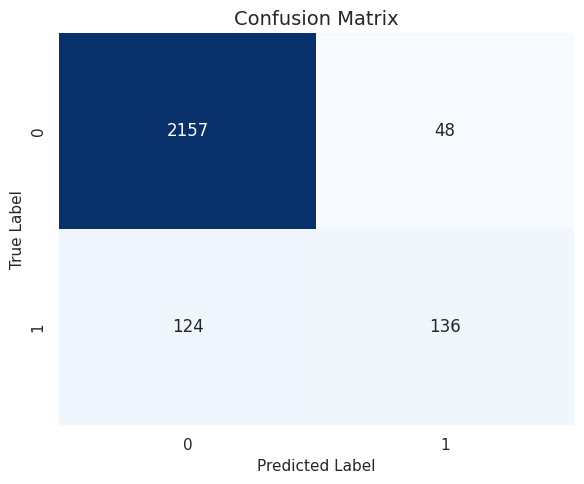

In [21]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

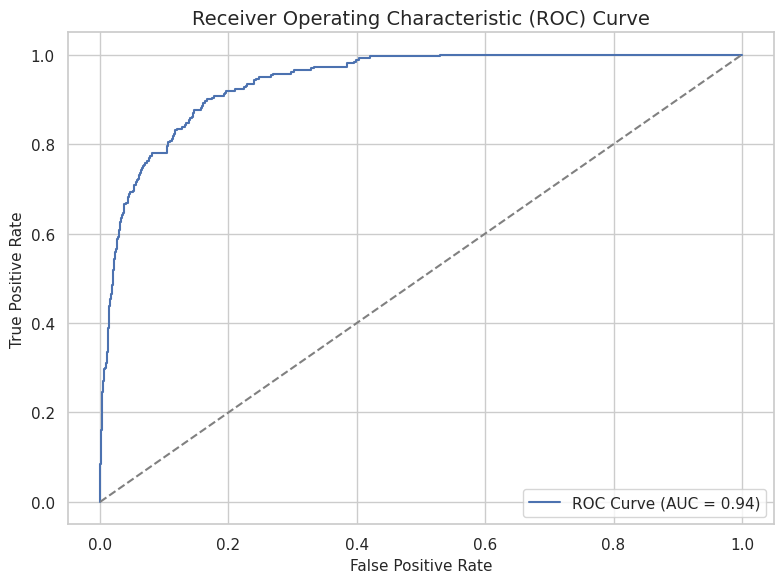

In [22]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

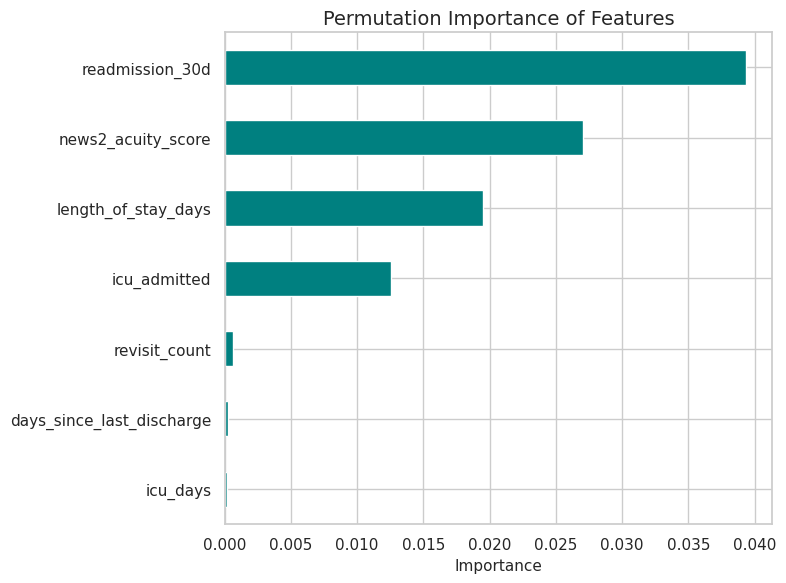

In [23]:
plt.figure(figsize=(8, 6))
feature_importance.plot(kind='barh', color='teal')
plt.title('Permutation Importance of Features')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

## Thank you..pls upvote!!!!!!!!!